# Eksperimen model: peringatan dini lonjakan harga cabai merah keriting (Depok)

Ini catatan eksperimen di balik temuan di `README.md`. Pertanyaannya: **bisakah kita memperingatkan 4 atau 8 minggu sebelumnya bahwa harga akan melonjak?**

Cara memakai:
- Jalankan sel **dari atas ke bawah**. Beberapa sel memakai variabel dari sel sebelumnya, dan generator acak `rng` (bootstrap) membuat rentang sedikit berbeda kalau urutannya diubah.
- Output yang tersimpan adalah hasil asli dari Colab. Di komputer sendiri, jalankan dari folder `notebooks/` dengan `data/raw/*.xlsx` tersedia.

Peringatan jujur sebelum membaca hasilnya:
- Bagian 2 memakai periode uji **2025 ke atas**. Periode itu sudah dibuka sekali, jadi jangan memilih apa pun berdasarkan hasilnya. Uji yang benar-benar bersih adalah log prediksi ke depan (`predictions/log.csv`).
- Bagian 6, 7, 8, dan 11 mencoba beberapa varian pada data yang sama. Varian yang "menang" bisa jadi hanya untung (forking paths), jadi anggap sebagai hipotesis, bukan kesimpulan.
- Sampelnya kecil: sekitar 261 minggu uji dan sekitar 48 minggu lonjakan.

## 1. Persiapan: data mingguan, fitur, pembagian latih dan uji
Harga harian dirata-ratakan per minggu (Senin sampai Minggu). Fitur hanya memakai masa lalu. Kolom `target` adalah harga `H` minggu ke depan.

In [1]:
import math
import numpy as np
import pandas as pd
import glob
import sys
H = 4                                   # horizon: tebak 4 minggu ke depan

# --- harga mingguan (sama dengan notebook 02) ---
try:                                    # di Colab: ambil dari Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    PATH = "/content/drive/MyDrive/proyek-harga-pangan/data-bersih/cabai_keriting_harian.csv"
    harga = pd.read_csv(PATH, index_col=0, parse_dates=True)["cabai_merah_keriting"]
except ImportError:                     # di komputer sendiri: baca file mentah di repo (jalankan dari folder notebooks/)
    sys.path.append("../src")
    from bersihkan import baca_pihps
    harga = baca_pihps(sorted(glob.glob("../data/raw/*.xlsx"))[-1])
mingguan = harga.resample("W-SUN").mean().ffill()

# --- tabel fitur (sama dengan notebook 02) ---
f = pd.DataFrame({"sekarang": mingguan})
f["lag1"]   = mingguan.shift(1)
f["lag4"]   = mingguan.shift(4)
f["ubah1"]  = mingguan / mingguan.shift(1) - 1
f["ubah4"]  = mingguan / mingguan.shift(4) - 1
f["rata4"]  = mingguan.rolling(4).mean()
f["rata52"] = mingguan.rolling(52).mean()
f["target"] = mingguan.shift(-H)

# --- kalender hari raya (sama dengan notebook 02) ---
fitri = pd.to_datetime(["2017-06-25","2018-06-15","2019-06-05","2020-05-24","2021-05-13",
                        "2022-05-02","2023-04-22","2024-04-10","2025-03-31","2026-03-21",
                        "2027-03-10"])
adha  = pd.to_datetime(["2017-09-01","2018-08-22","2019-08-11","2020-07-31","2021-07-20",
                        "2022-07-10","2023-06-29","2024-06-17","2025-06-06","2026-05-27",
                        "2027-05-17"])

def minggu_ke(hari_raya, t):
    berikut = hari_raya[hari_raya >= t].min()
    return math.ceil((berikut - t).days / 7)

f = f.dropna()
f["minggu_fitri"] = [minggu_ke(fitri, t) for t in f.index]
f["minggu_adha"]  = [minggu_ke(adha,  t) for t in f.index]

# --- pisah latih dan uji berdasarkan waktu ---
FITUR = [c for c in f.columns if c != "target"]     # semua kolom kecuali jawaban
train = f[f.index <  "2025-01-01"]
test  = f[f.index >= "2025-01-01"]

# --- guard ---
assert "target" not in FITUR, "target bocor ke fitur"
assert train.index.max() < test.index.min(), "latih dan uji tumpang tindih"

print(f.shape, len(train), len(test))     # (425, 10) 334 91
print(FITUR)

Mounted at /content/drive
(425, 10) 334 91
['sekarang', 'lag1', 'lag4', 'ubah1', 'ubah4', 'rata4', 'rata52', 'minggu_fitri', 'minggu_adha']


## 2. Model pertama dan pembanding (periode uji 2025+, sudah dibuka)
Tiga penebak: **A** rata-rata data latih, **B** persistence (harga tetap), dan LightGBM. Hasil: LightGBM tidak mengalahkan persistence.

In [2]:
import lightgbm as lgb

model = lgb.LGBMRegressor(random_state=0, verbose=-1)   # pengaturan bawaan
model.fit(train[FITUR], train.target)        # belajar: fitur data latih → target data latih
pred = model.predict(test[FITUR])      # tebak: fitur data uji

mae = lambda p, y: (y - p).abs().mean()
print("LightGBM         :", round(mae(pred, test.target)))
print("B persistence    :", round(mae(test.sekarang, test.target)))
print("A rata-rata latih:", round(mae(train.target.mean(), test.target)))

LightGBM         : 9163
B persistence    : 8672
A rata-rata latih: 10778


In [3]:
# target baru: perubahan persen 4 minggu ke depan
y_latih = train.target / train.sekarang - 1

model2 = lgb.LGBMRegressor(random_state=0, verbose=-1)
model2.fit(train[FITUR], y_latih)

persen = model2.predict(test[FITUR])               # tebakan: naik/turun berapa persen
pred2  = test.sekarang * (1 + persen)              # ubah kembali jadi Rupiah

print("rata-rata persen data latih:", round(y_latih.mean(), 3))
print("LightGBM (target persen)   :", round(mae(pred2, test.target)))
print("Persistence.               :", round(mae(test.sekarang, test.target)))

rata-rata persen data latih: 0.047
LightGBM (target persen)   : 8949
Persistence.               : 8672


## 3. Validasi bergulir 2020 sampai 2024, dengan purging
Untuk tiap tahun uji, model hanya dilatih dengan data yang jawabannya sudah diketahui sebelum tahun itu (`index + H minggu < awal`).

**Hasil:** LightGBM kalah dari persistence di kelima tahun. Rasio MAE terhadap persistence rata-rata 1,24 (target rupiah) dan 1,19 (target persen), jadi sekitar 20% lebih salah.

In [4]:
hasil = []                                    # tempat menyimpan skor tiap putaran

for tahun in range(2020, 2025):               # putaran: uji 2020, 2021, ..., 2024
    awal  = pd.Timestamp(f"{tahun}-01-01")
    akhir = pd.Timestamp(f"{tahun + 1}-01-01")

    uji   = f[(f.index >= awal) & (f.index < akhir)]      # periode ujian putaran ini
    latih = f[f.index + pd.Timedelta(weeks=H) < awal]     # hanya masa lalu (jawabannya sudah diketahui)

    assert latih.index.max() + pd.Timedelta(weeks=H) < awal, "jawaban latih bocor ke periode uji"

    model = lgb.LGBMRegressor(random_state=0, verbose=-1)
    model.fit(latih[FITUR], latih.target)
    tebak = model.predict(uji[FITUR])

    hasil.append({
        "tahun": tahun,
        "n_latih": len(latih),
        "A_rata2": round(mae(latih.target.mean(), uji.target)),
        "B_persistence": round(mae(uji.sekarang, uji.target)),
        "LightGBM": round(mae(tebak, uji.target)),
    })

tabel = pd.DataFrame(hasil).set_index("tahun")
tabel["LightGBM_menang?"] = tabel.LightGBM < tabel.B_persistence
print(tabel)

       n_latih  A_rata2  B_persistence  LightGBM  LightGBM_menang?
tahun                                                             
2020        69    12894           7926     11349             False
2021       121    10694           7639      8522             False
2022       173    19178          13493     16787             False
2023       225    12855           9943     13137             False
2024       278    13322          10352     11431             False


In [5]:
rasio = []

for tahun in range(2020, 2025):
    awal  = pd.Timestamp(f"{tahun}-01-01")
    akhir = pd.Timestamp(f"{tahun + 1}-01-01")
    uji   = f[(f.index >= awal) & (f.index < akhir)]
    latih = f[f.index + pd.Timedelta(weeks=H) < awal]
    assert latih.index.max() + pd.Timedelta(weeks=H) < awal, "jawaban latih bocor ke periode uji"

    mae_B = mae(uji.sekarang, uji.target)

    # Cara 1: model menebak harga Rupiah
    m1 = lgb.LGBMRegressor(random_state=0, verbose=-1)
    m1.fit(latih[FITUR], latih.target)
    tebak1 = m1.predict(uji[FITUR])

    # Cara 2: model menebak persen naik/turun, lalu diubah kembali ke Rupiah
    m2 = lgb.LGBMRegressor(random_state=0, verbose=-1)
    m2.fit(latih[FITUR], latih.target / latih.sekarang - 1)
    tebak2 = uji.sekarang * (1 + m2.predict(uji[FITUR]))

    rasio.append({
        "tahun": tahun,
        "rasio_rupiah": round(mae(tebak1, uji.target) / mae_B, 2),
        "rasio_persen": round(mae(tebak2, uji.target) / mae_B, 2),
    })

tabel2 = pd.DataFrame(rasio).set_index("tahun")
print(tabel2)
print(tabel2.mean().round(2))

       rasio_rupiah  rasio_persen
tahun                            
2020           1.43          1.18
2021           1.12          1.16
2022           1.24          1.10
2023           1.32          1.27
2024           1.10          1.23
rasio_rupiah    1.24
rasio_persen    1.19
dtype: float64


## 4. Dari angka ke alarm: lonjakan, TP/FP/FN, recall, precision
Lonjakan = harga `H` minggu kemudian naik lebih dari 25%. Karena lonjakan jarang (base rate sekitar 18%), kita menilai alarm dengan recall dan precision, bukan akurasi.

In [6]:
# 1) kumpulkan tebakan persen dari putaran validasi (2020-2024)
potongan = []
for tahun in range(2020, 2025):
    awal  = pd.Timestamp(f"{tahun}-01-01")
    akhir = pd.Timestamp(f"{tahun + 1}-01-01")
    uji   = f[(f.index >= awal) & (f.index < akhir)].copy()
    latih = f[f.index + pd.Timedelta(weeks=H) < awal]

    model = lgb.LGBMRegressor(random_state=0, verbose=-1)
    model.fit(latih[FITUR], latih.target / latih.sekarang - 1)
    uji["persen_tebak"] = model.predict(uji[FITUR])
    potongan.append(uji)

v = pd.concat(potongan)
v["lonjakan"] = (v.target / v.sekarang - 1) > 0.25      # kenyataan: lonjakan atau bukan

print("minggu:", len(v), "| lonjakan:", v.lonjakan.sum(), "| base rate:", round(v.lonjakan.mean(), 2))

# 2) fungsi pelapor: dari alarm (True/False per minggu) hitung TP, FP, FN, recall, precision
def lapor(nama, alarm):
    tp = (alarm & v.lonjakan).sum()
    fp = (alarm & ~v.lonjakan).sum()
    fn = (~alarm & v.lonjakan).sum()
    recall    = tp / (tp + fn)
    precision = tp / (tp + fp) if tp + fp > 0 else float("nan")
    print(f"{nama:28s} alarm={tp+fp:3d}  TP={tp:2d} FP={fp:3d} FN={fn:2d}  recall={recall:.2f}  precision={precision:.2f}")

# 3) tiga sistem alarm
lapor("alarm setiap minggu", pd.Series(True, index=v.index))
lapor("aturan: ubah4 > 0.10", v.ubah4 > 0.10)
lapor("LightGBM: tebakan > 0.10", v.persen_tebak > 0.10)

minggu: 261 | lonjakan: 48 | base rate: 0.18
alarm setiap minggu          alarm=261  TP=48 FP=213 FN= 0  recall=1.00  precision=0.18
aturan: ubah4 > 0.10         alarm= 86  TP=22 FP= 64 FN=26  recall=0.46  precision=0.26
LightGBM: tebakan > 0.10     alarm= 55  TP=12 FP= 43 FN=36  recall=0.25  precision=0.22


In [7]:
def titik(skor, tau):
    alarm = skor > tau
    tp = (alarm & v.lonjakan).sum()
    fp = (alarm & ~v.lonjakan).sum()
    fn = (~alarm & v.lonjakan).sum()
    return tp + fp, tp / (tp + fn), tp / (tp + fp)   # jumlah alarm, recall, precision

print("tau  | aturan: alarm recall prec | LightGBM: alarm recall prec")
for tau in [0.00, 0.02, 0.05, 0.08, 0.10, 0.15, 0.20, 0.25]:
    a = titik(v.ubah4, tau)
    b = titik(v.persen_tebak, tau)
    print(f"{tau:.2f} | {a[0]:4d} {a[1]:.2f} {a[2]:.2f} | {b[0]:4d} {b[1]:.2f} {b[2]:.2f}")

tau  | aturan: alarm recall prec | LightGBM: alarm recall prec
0.00 |  122 0.56 0.22 |   89 0.48 0.26
0.02 |  117 0.56 0.23 |   85 0.46 0.26
0.05 |  102 0.52 0.25 |   76 0.40 0.25
0.08 |   93 0.46 0.24 |   61 0.27 0.21
0.10 |   86 0.46 0.26 |   55 0.25 0.22
0.15 |   76 0.42 0.26 |   27 0.17 0.30
0.20 |   62 0.33 0.26 |   18 0.12 0.33
0.25 |   48 0.23 0.23 |   15 0.08 0.27


## 5. Kurva precision-recall, Average Precision, dan sensitivitas definisi lonjakan
AP merangkum seluruh kemungkinan ambang `tau`. Sel kedua mengecek apakah kesimpulan berubah kalau ambang lonjakan digeser.

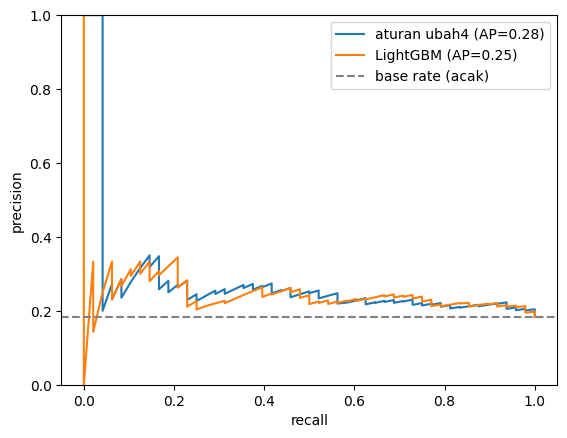

In [8]:
from sklearn.metrics import average_precision_score, precision_recall_curve
import matplotlib.pyplot as plt

for nama, skor in [("aturan ubah4", v.ubah4), ("LightGBM", v.persen_tebak)]:
    ap = average_precision_score(v.lonjakan, skor)
    p, r, _ = precision_recall_curve(v.lonjakan, skor)
    plt.plot(r, p, label=f"{nama} (AP={ap:.2f})")

plt.axhline(v.lonjakan.mean(), color="gray", linestyle="--", label="base rate (acak)")
plt.xlabel("recall"); plt.ylabel("precision"); plt.ylim(0, 1); plt.legend(); plt.show()

In [9]:
from sklearn.metrics import average_precision_score

naik = v.target / v.sekarang - 1          # kenaikan nyata, dalam persen
print("batas | lonjakan | base rate | AP aturan | AP LightGBM")
for batas in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]:
    y = naik > batas
    print(f"{batas:.2f}  | {y.sum():4d}     | {y.mean():.2f}      | {average_precision_score(y, v.ubah4):.2f}      | {average_precision_score(y, v.persen_tebak):.2f}")

batas | lonjakan | base rate | AP aturan | AP LightGBM
0.10  |   86     | 0.33      | 0.40      | 0.40
0.15  |   75     | 0.29      | 0.36      | 0.36
0.20  |   61     | 0.23      | 0.30      | 0.31
0.25  |   48     | 0.18      | 0.28      | 0.25
0.30  |   42     | 0.16      | 0.27      | 0.24
0.40  |   25     | 0.10      | 0.11      | 0.20


## 6. Eksperimen horizon: H = 1, 2, 4, 8
Lonjakan di sini didefinisikan sebagai 18% kenaikan terbesar. Lift = AP dibagi base rate (1,0 berarti sama dengan acak).

In [10]:
# bungkus pembuatan tabel fitur jadi fungsi, supaya bisa dicoba dengan H berbeda
def siapkan(Hh):
    g = pd.DataFrame({"sekarang": mingguan})
    g["lag1"]   = mingguan.shift(1)
    g["lag4"]   = mingguan.shift(4)
    g["ubah1"]  = mingguan / mingguan.shift(1) - 1
    g["ubah4"]  = mingguan / mingguan.shift(4) - 1
    g["rata4"]  = mingguan.rolling(4).mean()
    g["rata52"] = mingguan.rolling(52).mean()
    g["target"] = mingguan.shift(-Hh)
    g = g.dropna()
    g["minggu_fitri"] = [minggu_ke(fitri, t) for t in g.index]
    g["minggu_adha"]  = [minggu_ke(adha,  t) for t in g.index]
    return g

# bungkus putaran validasi 2020-2024 jadi fungsi
def validasi(Hh):
    g = siapkan(Hh)
    fitur = [c for c in g.columns if c != "target"]
    potongan = []
    for tahun in range(2020, 2025):
        awal  = pd.Timestamp(f"{tahun}-01-01")
        akhir = pd.Timestamp(f"{tahun + 1}-01-01")
        uji   = g[(g.index >= awal) & (g.index < akhir)].copy()
        latih = g[g.index + pd.Timedelta(weeks=Hh) < awal]
        model = lgb.LGBMRegressor(random_state=0, verbose=-1)
        model.fit(latih[fitur], latih.target / latih.sekarang - 1)
        uji["tebak"] = model.predict(uji[fitur])
        potongan.append(uji)
    return pd.concat(potongan)

print("H | lonjakan | base | lift aturan | lift LightGBM")
for Hh in [1, 2, 4, 8]:
    w = validasi(Hh)
    naik = w.target / w.sekarang - 1
    y = naik > naik.quantile(0.82)          # 18% kenaikan terbesar = lonjakan
    base = y.mean()
    lift_aturan = average_precision_score(y, w.ubah4)  / base
    lift_model  = average_precision_score(y, w.tebak) / base
    print(f"{Hh} | {y.sum():4d} | {base:.2f} | x{lift_aturan:.1f} | x{lift_model:.1f}")

H | lonjakan | base | lift aturan | lift LightGBM
1 |   47 | 0.18 | x1.4 | x1.8
2 |   47 | 0.18 | x1.5 | x1.4
4 |   47 | 0.18 | x1.5 | x1.4
8 |   47 | 0.18 | x0.9 | x1.8


## 7. Eksperimen pengaturan model (hyperparameter) dengan rentang bootstrap
`rentang` memberi interval 90% memakai block bootstrap (blok 8 minggu). Pengaturan yang lebih kecil terlihat lebih baik di H=4, tapi itu muncul setelah mencoba beberapa varian.

In [11]:
import numpy as np
from sklearn.metrics import average_precision_score
rng = np.random.default_rng(0)

def validasi(Hh, **par):               # sama seperti sebelumnya, tapi pengaturan model bisa diganti lewat par
    g = siapkan(Hh)
    fitur = [c for c in g.columns if c != "target"]
    potongan = []
    for tahun in range(2020, 2025):
        awal  = pd.Timestamp(f"{tahun}-01-01")
        akhir = pd.Timestamp(f"{tahun + 1}-01-01")
        uji   = g[(g.index >= awal) & (g.index < akhir)].copy()
        latih = g[g.index + pd.Timedelta(weeks=Hh) < awal]
        model = lgb.LGBMRegressor(random_state=0, verbose=-1, **par)
        model.fit(latih[fitur], latih.target / latih.sekarang - 1)
        uji["tebak"] = model.predict(uji[fitur])
        potongan.append(uji)
    return pd.concat(potongan)

def rentang(y, skor, blok=8, B=500):   # rentang 5%-95% dari lift (bootstrap per blok minggu)
    y, skor = y.values, skor.values
    n = len(y); hasil = []
    for _ in range(B):
        mulai = rng.integers(0, n - blok + 1, int(np.ceil(n / blok)))
        idx = np.concatenate([np.arange(a, a + blok) for a in mulai])[:n]
        if y[idx].sum() == 0:
            continue
        hasil.append(average_precision_score(y[idx], skor[idx]) / y[idx].mean())
    return np.percentile(hasil, [5, 95])

VARIAN = {
    "bawaan":       {},
    "kecil":        dict(num_leaves=7, learning_rate=0.05, n_estimators=100, min_child_samples=20),
    "sangat kecil": dict(num_leaves=3, learning_rate=0.03, n_estimators=100, min_child_samples=30),
}

for Hh in [4, 8]:
    for nama, par in VARIAN.items():
        w = validasi(Hh, **par)
        naik = w.target / w.sekarang - 1
        y = naik > naik.quantile(0.82)
        lift = average_precision_score(y, w.tebak) / y.mean()
        lo, hi = rentang(y, w.tebak)
        print(f"H={Hh} {nama:13s} lift=x{lift:.2f}  rentang {lo:.1f}-{hi:.1f}")

H=4 bawaan        lift=x1.36  rentang 1.1-2.1
H=4 kecil         lift=x1.61  rentang 1.1-2.7
H=4 sangat kecil  lift=x2.17  rentang 1.6-3.3
H=8 bawaan        lift=x1.78  rentang 1.3-2.7
H=8 kecil         lift=x1.67  rentang 1.2-2.5
H=8 sangat kecil  lift=x1.39  rentang 1.1-2.2


## 8. Eksperimen fitur tambahan `rasio52`
Harga sekarang dibanding rata-rata 52 minggu. Selisihnya kecil dan masih tercakup rentang ketidakpastian.

In [12]:
def validasi(Hh, rasio=False, **par):
    g = siapkan(Hh)
    if rasio:
        g["rasio52"] = g.sekarang / g.rata52 - 1
    fitur = [c for c in g.columns if c != "target"]
    potongan = []
    for tahun in range(2020, 2025):
        awal  = pd.Timestamp(f"{tahun}-01-01")
        akhir = pd.Timestamp(f"{tahun + 1}-01-01")
        uji   = g[(g.index >= awal) & (g.index < akhir)].copy()
        latih = g[g.index + pd.Timedelta(weeks=Hh) < awal]
        model = lgb.LGBMRegressor(random_state=0, verbose=-1, **par)
        model.fit(latih[fitur], latih.target / latih.sekarang - 1)
        uji["tebak"] = model.predict(uji[fitur])
        potongan.append(uji)
    return pd.concat(potongan)

for Hh in [4, 8]:
    for rasio in [False, True]:
        w = validasi(Hh, rasio=rasio)
        naik = w.target / w.sekarang - 1
        y = naik > naik.quantile(0.82)
        lift = average_precision_score(y, w.tebak) / y.mean()
        lo, hi = rentang(y, w.tebak)
        print(f"H={Hh} rasio52={str(rasio):5s} lift=x{lift:.2f}  rentang {lo:.1f}-{hi:.1f}")

H=4 rasio52=False lift=x1.36  rentang 1.0-2.0
H=4 rasio52=True  lift=x1.49  rentang 1.1-2.3
H=8 rasio52=False lift=x1.78  rentang 1.2-2.7
H=8 rasio52=True  lift=x1.64  rentang 1.2-2.6


## 9. Mengapa tebakan regresi "mengerut"
Tebakan model untuk minggu lonjakan hampir sama dengan minggu biasa, jauh di bawah kenyataan. Jadi tebakan ini berguna sebagai skor peringkat, bukan sebagai ramalan besar kenaikan.

rata-rata tebakan   | minggu lonjakan: -0.02 | minggu biasa: -0.09
rata-rata kenyataan | minggu lonjakan: 0.51 | minggu biasa: -0.07


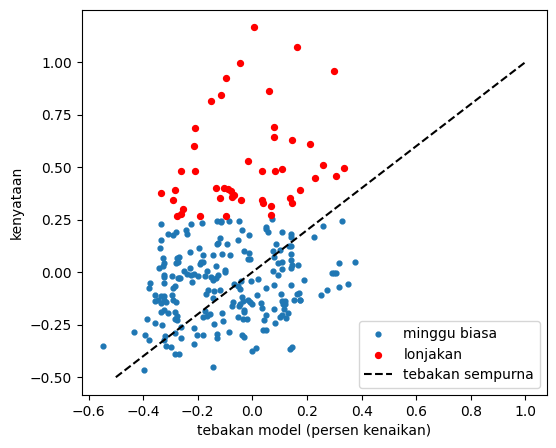

In [13]:
import matplotlib.pyplot as plt

w = validasi(4)
naik = w.target / w.sekarang - 1
y = naik > naik.quantile(0.82)

print("rata-rata tebakan   | minggu lonjakan:", round(w.tebak[y].mean(), 2), "| minggu biasa:", round(w.tebak[~y].mean(), 2))
print("rata-rata kenyataan | minggu lonjakan:", round(naik[y].mean(), 2), "| minggu biasa:", round(naik[~y].mean(), 2))

plt.figure(figsize=(6, 5))
plt.scatter(w.tebak[~y], naik[~y], s=12, label="minggu biasa")
plt.scatter(w.tebak[y], naik[y], s=18, color="red", label="lonjakan")
plt.plot([-0.5, 1.0], [-0.5, 1.0], "k--", label="tebakan sempurna")
plt.xlabel("tebakan model (persen kenaikan)"); plt.ylabel("kenyataan")
plt.legend(); plt.show()

## 10. Kalibrasi: apakah probabilitas model bisa dipercaya?
Klasifikator bawaan terlalu percaya diri (bin atas: klaim 82%, kenyataan 30%). Sel berikutnya menambahkan interval Wilson 90%, supaya terlihat bahwa bin kecil sangat tidak pasti.

In [14]:
def validasi_peluang(Hh, batas=0.25):
    g = siapkan(Hh)
    fitur = [c for c in g.columns if c != "target"]
    potongan = []
    for tahun in range(2020, 2025):
        awal  = pd.Timestamp(f"{tahun}-01-01")
        akhir = pd.Timestamp(f"{tahun + 1}-01-01")
        uji   = g[(g.index >= awal) & (g.index < akhir)].copy()
        latih = g[g.index + pd.Timedelta(weeks=Hh) < awal]
        kelas = (latih.target / latih.sekarang - 1) > batas        # lonjakan atau bukan
        model = lgb.LGBMClassifier(random_state=0, verbose=-1)
        model.fit(latih[fitur], kelas)
        uji["peluang"] = model.predict_proba(uji[fitur])[:, 1]
        potongan.append(uji)
    return pd.concat(potongan)

w = validasi_peluang(4)
y = (w.target / w.sekarang - 1) > 0.25
kotak = pd.cut(w.peluang, [0, 0.1, 0.2, 0.4, 1.0])
tabel = pd.DataFrame({"kotak": kotak, "peluang": w.peluang, "lonjakan": y})
print(tabel.groupby("kotak", observed=True).agg(
    minggu=("lonjakan", "size"),
    peluang_model=("peluang", "mean"),
    lonjakan_nyata=("lonjakan", "mean")).round(2))

            minggu  peluang_model  lonjakan_nyata
kotak                                            
(0.0, 0.1]     202           0.02            0.16
(0.1, 0.2]      26           0.16            0.19
(0.2, 0.4]      23           0.26            0.30
(0.4, 1.0]      10           0.82            0.30


In [15]:
from statsmodels.stats.proportion import proportion_confint

kotak = pd.cut(w.peluang, [0, 0.1, 0.4, 1.0])
tabel = pd.DataFrame({"kotak": kotak, "lonjakan": y})
for k, d in tabel.groupby("kotak", observed=True):
    n = len(d)                       # jumlah minggu di kotak ini
    m = int(d.lonjakan.sum())        # berapa yang melonjak
    lo, hi = proportion_confint(m, n, alpha=0.10, method="wilson")
    print(f"peluang model {str(k):10s}: {m:2d} dari {n:3d} minggu melonjak = {m/n:.0%}  (rentang 90%: {lo:.0%} - {hi:.0%})")

peluang model (0.0, 0.1]: 33 dari 202 minggu melonjak = 16%  (rentang 90%: 13% - 21%)
peluang model (0.1, 0.4]: 12 dari  49 minggu melonjak = 24%  (rentang 90%: 16% - 36%)
peluang model (0.4, 1.0]:  3 dari  10 minggu melonjak = 30%  (rentang 90%: 13% - 56%)


## 11. Hipotesis: membuang fitur kalender hari raya
Membuang `minggu_fitri` dan `minggu_adha` menaikkan lift. Ini ditemukan setelah banyak percobaan pada data yang sama, jadi diperlakukan sebagai **hipotesis**. Log prediksi ke depan mencatat versi dengan dan tanpa kalender berdampingan untuk mengujinya.

In [16]:
def validasi(Hh, rasio=False, buang=(), **par):
    g = siapkan(Hh)
    if rasio:
        g["rasio52"] = g.sekarang / g.rata52 - 1
    fitur = [c for c in g.columns if c != "target" and c not in buang]
    potongan = []
    for tahun in range(2020, 2025):
        awal  = pd.Timestamp(f"{tahun}-01-01")
        akhir = pd.Timestamp(f"{tahun + 1}-01-01")
        uji   = g[(g.index >= awal) & (g.index < akhir)].copy()
        latih = g[g.index + pd.Timedelta(weeks=Hh) < awal]
        model = lgb.LGBMRegressor(random_state=0, verbose=-1, **par)
        model.fit(latih[fitur], latih.target / latih.sekarang - 1)
        uji["tebak"] = model.predict(uji[fitur])
        potongan.append(uji)
    return pd.concat(potongan)

KALENDER = ["minggu_fitri", "minggu_adha"]
for Hh in [4, 8]:
    for nama, buang in [("semua fitur", ()), ("tanpa kalender", KALENDER)]:
        w = validasi(Hh, buang=buang)
        naik = w.target / w.sekarang - 1
        y = naik > naik.quantile(0.82)
        lift = average_precision_score(y, w.tebak) / y.mean()
        lo, hi = rentang(y, w.tebak)
        print(f"H={Hh} {nama:15s} lift=x{lift:.2f}  rentang {lo:.1f}-{hi:.1f}")

H=4 semua fitur     lift=x1.36  rentang 1.1-2.2
H=4 tanpa kalender  lift=x1.87  rentang 1.4-2.7
H=8 semua fitur     lift=x1.78  rentang 1.3-2.7
H=8 tanpa kalender  lift=x2.81  rentang 2.0-4.2


## Kesimpulan jujur

- Pada rata-rata kesalahan (MAE), LightGBM **tidak** mengalahkan tebakan "harga tetap".
- Sebagai peringkat minggu lonjakan, ada sedikit informasi (lift sekitar 1,4 sampai 1,8), tetapi interval lebar dan di H=4 tidak jelas lebih baik daripada aturan satu baris (`ubah4`).
- Probabilitas bawaan terlalu percaya diri. Untuk komunikasi ke pembaca, lebih jujur memakai bentuk "k dari n minggu serupa melonjak (interval), dibanding base rate".
- Temuan tentang fitur kalender adalah hipotesis, diuji lewat log prediksi ke depan.